# OHRC/TMC-2 → LRO NAC Image Registration

## 1. Install dependencies

In [1]:
!pip -q install opencv-contrib-python-headless pandas matplotlib

# SuperGlue is optional. Set USE_SUPERGLUE=False below if you want a pure-CPU SIFT run.
!rm -rf /content/SuperGluePretrainedNetwork
!git clone -q https://github.com/magicleap/SuperGluePretrainedNetwork.git /content/SuperGluePretrainedNetwork
!bash /content/SuperGluePretrainedNetwork/download_models.sh >/dev/null 2>&1 || true

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.5/69.5 MB 11.0 MB/s eta 0:00:00


## 2. Mount Google Drive and configure the dataset

Recommended Drive layout:

```text
MyDrive/  (inputs live at this root, as in your Drive screenshots)
├── ohrc/   # product folder(s): browse/ + data/ + geometry/ + miscellaneous/
├── tmc2/  # same product-folder layout when available
├── nac/   # NAC .img + _meta.json + optional preview .png
└── Chandrayaan_Registration/outputs/  # notebook writes results here
```

You can also point the variables below directly at existing files. Leave them as `None` to use automatic recursive discovery inside `PROJECT_ROOT`.

In [ ]:
from google.colab import drive
from pathlib import Path
import os, sys, json, math, time, gc, warnings
import numpy as np
import pandas as pd
import cv2
import torch
import matplotlib.pyplot as plt

drive.mount('/content/drive')

PROJECT_ROOT = Path('/content/drive/MyDrive')
OUTPUT_ROOT = Path('/content/drive/MyDrive/Chandrayaan_Registration/outputs')
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# --------- CHANGE ONLY THESE IF AUTO-DISCOVERY DOES NOT FIND YOUR FILES ---------
SENSOR = 'ohrc'                 # 'ohrc' or 'tmc'
SOURCE_IMG = None               # e.g. Path('/.../ch2_..._d_img_d18.img')
SOURCE_PREVIEW_PNG = None     # e.g. OHRC browse ..._b_brw_d18.png; fallback when the source .img is not staged
SOURCE_XML = None               # e.g. Path('/.../ch2_..._d_img_d18.xml')
SOURCE_GEO_CSV = None           # optional geometry CSV
REFERENCE_IMG = None            # e.g. Path('/.../M1350459544RE.img')
REFERENCE_PREVIEW_PNG = None    # e.g. Path('/.../M1350459544RE.png'); lightweight fallback when the NAC .img is not staged
REFERENCE_META = None            # e.g. Path('/.../M1350459544RE_meta.json')

USE_PREVIEWS_ONLY = True          #Set False on the workstation for the full-.img run
USE_SUPERGLUE = True            # True = SuperGlue primary; False = SIFT only
USE_PIECEWISE = False           # keep False for the first real benchmark
MAX_COARSE_DIM = 1800           # global SIFT localization image size
TILE_PX = 1200                  # local matching tile size
TILE_OVERLAP = 200
MAX_MATCH_SIDE = 1400           # max long side per local matcher tile
MAX_LOCAL_TILES = 5000
RANSAC_THRESH_PX = 3.0
MIN_INLIERS = 15
MIN_INLIER_RATIO = 0.05
UNIFORM_GRID = (8, 8)
MAX_POINTS_PER_CELL = 12
SUBPIXEL_REFINE = True
SUBPIXEL_WIN = (5, 5)
SUBPIXEL_MAX_SHIFT = 1.5

print('Project root:', PROJECT_ROOT)
print('Output root :', OUTPUT_ROOT)

Mounted at /content/drive
Project root: /content/drive/MyDrive
Output root : /content/drive/MyDrive/Chandrayaan_Registration/outputs


## 3. Locate and parse the real product metadata

The source PDS4 label supplies shape, dtype, GSD, illumination and corner coordinates. The supplied NAC metadata supplies shape, GSD, illumination and footprint information.

In [3]:
PDS4_DTYPE = {
    'UnsignedByte': np.uint8,
    'SignedByte': np.int8,
    'UnsignedLSB2': '<u2', 'UnsignedMSB2': '>u2',
    'UnsignedLSB4': '<u4', 'UnsignedMSB4': '>u4',
}

def strip_ns(tag):
    return tag.split('}')[-1]

def xml_first(root, tag):
    for el in root.iter():
        if strip_ns(el.tag) == tag:
            return el.text.strip() if el.text else None
    return None

def xml_all(root, tag):
    return [el for el in root.iter() if strip_ns(el.tag) == tag]

def child_text(el, tag):
    for c in el:
        if strip_ns(c.tag) == tag:
            return c.text.strip() if c.text else None
    return None

def parse_source_xml(path):
    import xml.etree.ElementTree as ET
    root = ET.parse(path).getroot()
    shape = {}
    for ax in xml_all(root, 'Axis_Array'):
        n = child_text(ax, 'axis_name')
        e = child_text(ax, 'elements')
        if n and e: shape[n] = int(e)
    corners = None
    for block_name in ('Refined_Corner_Coordinates', 'System_Level_Coordinates'):
        blocks = xml_all(root, block_name)
        if blocks:
            d = {}
            for c in blocks[0]:
                if c.text:
                    try: d[strip_ns(c.tag)] = float(c.text)
                    except ValueError: pass
            needed = ['upper_left_latitude','upper_left_longitude','upper_right_latitude','upper_right_longitude',
                      'lower_right_latitude','lower_right_longitude','lower_left_latitude','lower_left_longitude']
            if all(k in d for k in needed):
                corners = {k:d[k] for k in needed}
                break
    def f(tag):
        v = xml_first(root, tag)
        try: return float(v) if v is not None else None
        except ValueError: return None
    dtype_name = xml_first(root, 'data_type')
    return {
        'img_file': xml_first(root, 'file_name'),
        'shape': (shape.get('Line'), shape.get('Sample')),
        'dtype': PDS4_DTYPE.get(dtype_name, np.uint8),
        'offset': int(float(xml_first(root, 'offset') or 0)),
        'corners': corners,
        'pixel_resolution_m': f('pixel_resolution'),
        'sun_azimuth_deg': f('sun_azimuth'),
        'sun_elevation_deg': f('sun_elevation'),
        'incidence_angle_deg': f('solar_incidence'),
        'roll_deg': f('roll'), 'pitch_deg': f('pitch'), 'yaw_deg': f('yaw'),
        'spacecraft_altitude_km': f('spacecraft_altitude'),
        'projection': xml_first(root, 'projection'),
        'area': xml_first(root, 'area'),
    }

def parse_nac_meta(path):
    d = json.loads(Path(path).read_text())
    bits = int(d.get('sample_bits', 8))
    return {
        'img_file': d.get('product_id'),
        'shape': (int(d['shape_lines']), int(d['shape_samples'])),
        'dtype': np.uint8 if bits == 8 else '<u2',
        'offset': 0,
        'corners': d.get('corners'),
        'pixel_resolution_m': d.get('resolution_m'),
        'sun_azimuth_deg': d.get('sub_solar_azimuth_deg'),
        'sun_elevation_deg': None,
        'incidence_angle_deg': d.get('incidence_angle_deg'),
        'spacecraft_altitude_km': d.get('spacecraft_altitude_km', d.get('spacecraft_altitude')),
        'center_latitude': d.get('center_latitude'), 'center_longitude': d.get('center_longitude'),
    }

def discover(patterns, root=PROJECT_ROOT):
    hits=[]
    for p in patterns:
        hits.extend(root.rglob(p))
    return sorted(set(hits))

def choose_single(candidates, label):
    if not candidates:
        return None
    if len(candidates) > 1:
        print(f'{label}: multiple candidates found; using the first sorted path:')
        for x in candidates[:8]: print(' ', x)
    return candidates[0]

if SOURCE_XML is None:
    source_xml_candidates = discover(['*.xml'])
    # Prefer calibrated source labels whose name contains the selected sensor.
    key = 'ohr' if SENSOR == 'ohrc' else 'tmc'
    source_xml_candidates = [p for p in source_xml_candidates if key in p.name.lower() and '_brw_' not in p.name.lower() and '_grd_' not in p.name.lower()]
    SOURCE_XML = choose_single(source_xml_candidates, 'Source XML')

if SOURCE_IMG is None and SOURCE_XML is not None:
    source_meta_tmp = parse_source_xml(SOURCE_XML)
    expected = source_meta_tmp['img_file']
    if expected:
        exact = list(PROJECT_ROOT.rglob(expected))
        SOURCE_IMG = choose_single(exact, 'Source IMG')
    if SOURCE_IMG is None:
        SOURCE_IMG = choose_single(discover(['*.img','*.IMG']), 'Source IMG')

if SOURCE_PREVIEW_PNG is None:
    _key2 = 'ohr' if SENSOR == 'ohrc' else 'tmc'
    _brw = [p for p in discover(['*.png']) if _key2 in p.name.lower() and '_brw_' in p.name.lower()]
    SOURCE_PREVIEW_PNG = choose_single(_brw, 'Source preview PNG')

if SOURCE_GEO_CSV is None:
    geo_candidates = discover(['*.csv'])
    geo_candidates = [p for p in geo_candidates if 'grd' in p.name.lower()]
    SOURCE_GEO_CSV = choose_single(geo_candidates, 'Source geometry CSV')

if REFERENCE_META is None:
    REFERENCE_META = choose_single(discover(['*_meta.json']), 'NAC metadata')
if REFERENCE_IMG is None and REFERENCE_META is not None:
    nac_id = parse_nac_meta(REFERENCE_META)['img_file']
    exact = list(PROJECT_ROOT.rglob(nac_id + '.img')) + list(PROJECT_ROOT.rglob(nac_id + '.IMG')) if nac_id else []
    REFERENCE_IMG = choose_single(exact, 'NAC IMG')
    if REFERENCE_IMG is None:
        # Search by product id anywhere in the name.
        candidates = [p for p in discover(['*.img','*.IMG']) if nac_id and nac_id.lower() in p.name.lower()]
        REFERENCE_IMG = choose_single(candidates, 'NAC IMG')

print('\nSelected files')
print('SOURCE_IMG     =', SOURCE_IMG)
print('SOURCE_PREVIEW_PNG =', SOURCE_PREVIEW_PNG)
print('SOURCE_XML     =', SOURCE_XML)
print('SOURCE_GEO_CSV =', SOURCE_GEO_CSV)
print('REFERENCE_IMG  =', REFERENCE_IMG)
print('REFERENCE_META =', REFERENCE_META)

if SOURCE_XML is None or (SOURCE_IMG is None and SOURCE_PREVIEW_PNG is None) or REFERENCE_META is None:
    raise FileNotFoundError('Could not locate source XML + (source IMG or preview PNG) and NAC metadata. Set the paths manually in the config cell.')

src_meta = parse_source_xml(SOURCE_XML)
ref_meta = parse_nac_meta(REFERENCE_META)
print('\nSOURCE META:', src_meta)
print('\nREFERENCE META:', ref_meta)

NAC metadata: multiple candidates found; using the first sorted path:
  /content/drive/MyDrive/M1350459544RC_meta.json
  /content/drive/MyDrive/nac/M1350459544RE/M1350459544RE_meta.json
  /content/drive/MyDrive/processed/nac/M1350459544RE_meta.json
  /content/drive/MyDrive/processed/ohrc/ch2_ohr_ncp_20210401T2357376656_d_img_d18_meta.json

Selected files
SOURCE_IMG     = /content/drive/MyDrive/ohrc/ch2_ohr_ncp_20210401T2357376656_d_img_d18/data/calibrated/20210401/ch2_ohr_ncp_20210401T2357376656_d_img_d18.img
SOURCE_PREVIEW_PNG = /content/drive/MyDrive/ohrc/ch2_ohr_ncp_20210401T2357376656_d_img_d18/browse/calibrated/20210401/ch2_ohr_ncp_20210401T2357376656_b_brw_d18.png
SOURCE_XML     = /content/drive/MyDrive/ohrc/ch2_ohr_ncp_20210401T2357376656_d_img_d18/data/calibrated/20210401/ch2_ohr_ncp_20210401T2357376656_d_img_d18.xml
SOURCE_GEO_CSV = /content/drive/MyDrive/ohrc/ch2_ohr_ncp_20210401T2357376656_d_img_d18/geometry/calibrated/20210401/ch2_ohr_ncp_20210401T2357376656_g_grd_d18.csv
R

## 4. Validate metadata and the footprint/GSD relationship

In [4]:
MOON_RADIUS_KM = 1737.4

def haversine_m(a_lat,a_lon,b_lat,b_lon):
    p1,p2=np.deg2rad(a_lat),np.deg2rad(b_lat)
    dlat=np.deg2rad(b_lat-a_lat); dlon=np.deg2rad(b_lon-a_lon)
    aa=np.sin(dlat/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dlon/2)**2
    return 2*MOON_RADIUS_KM*1000*np.arcsin(np.sqrt(aa))

def corner_ring(c):
    return np.array([
        [c['upper_left_longitude'], c['upper_left_latitude']],
        [c['upper_right_longitude'], c['upper_right_latitude']],
        [c['lower_right_longitude'], c['lower_right_latitude']],
        [c['lower_left_longitude'], c['lower_left_latitude']],
    ], dtype=float)

def footprint_report(meta, name):
    h,w=meta['shape']; gsd=meta['pixel_resolution_m']; c=meta.get('corners')
    print(f'--- {name} ---')
    print('shape:', (h,w), 'GSD:', gsd, 'm/px')
    if c:
        top=haversine_m(c['upper_left_latitude'],c['upper_left_longitude'],c['upper_right_latitude'],c['upper_right_longitude'])
        bottom=haversine_m(c['lower_left_latitude'],c['lower_left_longitude'],c['lower_right_latitude'],c['lower_right_longitude'])
        left=haversine_m(c['upper_left_latitude'],c['upper_left_longitude'],c['lower_left_latitude'],c['lower_left_longitude'])
        right=haversine_m(c['upper_right_latitude'],c['upper_right_longitude'],c['lower_right_latitude'],c['lower_right_longitude'])
        expected_x=w*gsd if gsd else None; expected_y=h*gsd if gsd else None
        print(f'footprint top/bottom: {top/1000:.2f}/{bottom/1000:.2f} km | expected width: {expected_x/1000:.2f} km')
        print(f'footprint left/right: {left/1000:.2f}/{right/1000:.2f} km | expected height: {expected_y/1000:.2f} km')
        if expected_x and expected_y:
            rx=((top+bottom)/2)/expected_x; ry=((left+right)/2)/expected_y
            print(f'footprint/GSD ratios: width={rx:.2f}, height={ry:.2f} (≈1 is good)')
            if max(rx,1/rx,ry,1/ry) > 1.5:
                print('WARNING: corner footprint and GSD/dimensions disagree strongly; do not trust automatic geospatial cropping.')
    print('sun azimuth/elevation:', meta.get('sun_azimuth_deg'), meta.get('sun_elevation_deg'))
    print('incidence:', meta.get('incidence_angle_deg'))

footprint_report(src_meta, SENSOR.upper())
footprint_report(ref_meta, 'LRO NAC')

--- OHRC ---
shape: (90148, 12000) GSD: 0.26 m/px
footprint top/bottom: 3.33/3.33 km | expected width: 3.12 km
footprint left/right: 25.18/25.18 km | expected height: 23.44 km
footprint/GSD ratios: width=1.07, height=1.07 (≈1 is good)
sun azimuth/elevation: 270.918646 9.909709
incidence: 80.090291
--- LRO NAC ---
shape: (52224, 2532) GSD: 1.6053232034765612 m/px
footprint top/bottom: 3.85/4.09 km | expected width: 4.06 km
footprint left/right: 87.23/87.21 km | expected height: 83.84 km
footprint/GSD ratios: width=0.98, height=1.04 (≈1 is good)
sun azimuth/elevation: 181.7 None
incidence: 72.16


## 5. Read only the pixels we need

The source OHRC product is about 1.08 GB. It must not be blindly loaded into RAM. We use `memmap` and small decimated previews for coarse localization.

Using source preview PNG (rapid-look; full .img deferred): /content/drive/MyDrive/ohrc/ch2_ohr_ncp_20210401T2357376656_d_img_d18/browse/calibrated/20210401/ch2_ohr_ncp_20210401T2357376656_b_brw_d18.png
Reference preview PNG auto-found: /content/drive/MyDrive/Chandrayaan_Registration/outputs/ohrc_to_nac_ch2_ohr_ncp_20210401T2357376656_d_img_d18/coarse_warp.png
Using NAC preview PNG (rapid-look; full .img deferred): /content/drive/MyDrive/Chandrayaan_Registration/outputs/ohrc_to_nac_ch2_ohr_ncp_20210401T2357376656_d_img_d18/coarse_warp.png
Source preview (PNG): (9014, 1200) -> (4507, 600), strides x=20.000 y=20.002
Pixel mode: PREVIEW-PNG staged demo (USE_PREVIEWS_ONLY=True)
Reference preview (PNG): (679, 33) -> (679, 33), strides x=76.727 y=76.913


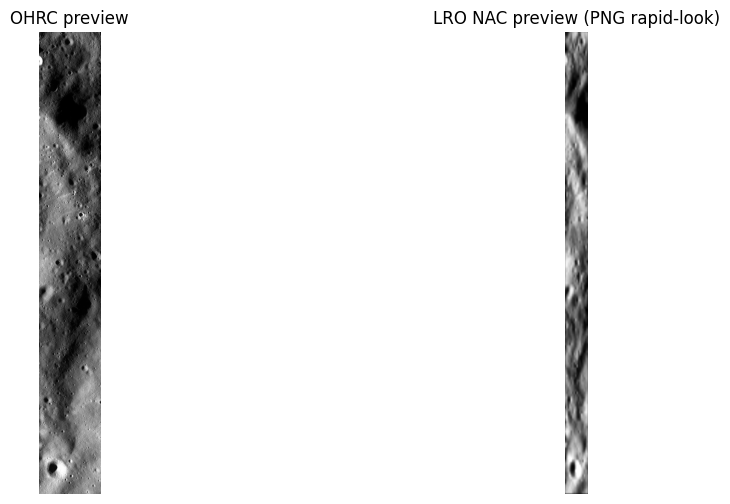

In [5]:
def open_memmap(path, meta):
    h,w = meta['shape']; dt=np.dtype(meta['dtype']); off=int(meta.get('offset',0))
    expected=h*w*dt.itemsize
    available=Path(path).stat().st_size-off
    if available < expected:
        raise ValueError(f'{path} is too small: need {expected:,} bytes, have {available:,}. Check IMG/label pairing.')
    return np.memmap(path, dtype=dt, mode='r', offset=off, shape=(h,w))

def decimated_preview(mm, max_dim=1800):
    h,w=mm.shape
    stride=max(1,int(math.ceil(max(h,w)/max_dim)))
    a=np.asarray(mm[::stride,::stride])
    a=a.astype(np.float32)
    lo,hi=np.percentile(a[np.isfinite(a)],[0.5,99.5])
    if hi<=lo: hi=lo+1
    return np.clip((a-lo)/(hi-lo)*255,0,255).astype(np.uint8), stride

def normalize8(a):
    a=np.asarray(a).astype(np.float32)
    finite=a[np.isfinite(a)]
    lo,hi=np.percentile(finite,[0.5,99.5]) if finite.size else (0,1)
    if hi<=lo: hi=lo+1
    return np.clip((a-lo)/(hi-lo)*255,0,255).astype(np.uint8)

def enhance_lunar(a, gamma=1.0):
    a=normalize8(a)
    clahe=cv2.createCLAHE(clipLimit=2.0,tileGridSize=(8,8))
    out=clahe.apply(a)
    if gamma != 1.0:
        out=np.clip((out.astype(np.float32)/255.0)**gamma*255,0,255).astype(np.uint8)
    return out

src_mm=None
src_is_preview_png=False
src_stride_x=src_stride_y=None
src_png_native=None; src_png_sx=src_png_sy=None
if not globals().get('USE_PREVIEWS_ONLY', False) and SOURCE_IMG is not None and Path(SOURCE_IMG).exists():
    src_mm=open_memmap(SOURCE_IMG, src_meta)
    print('Source memmap:', src_mm.shape, src_mm.dtype)
elif SOURCE_PREVIEW_PNG is not None and Path(SOURCE_PREVIEW_PNG).exists():
    src_is_preview_png=True
    print('Using source preview PNG (rapid-look; full .img deferred):', SOURCE_PREVIEW_PNG)
else:
    raise FileNotFoundError('No source pixels: stage the source .img or its preview .png (browse ..._b_brw_d18.png) on Drive.')

# Reference pixels: prefer the NAC .img; otherwise accept a preview .png
# (same rapid-look pattern as the OHRC browse preview). Strides below map
# preview pixels back to full-res NAC pixels for the H_full computation.
ref_mm=None
ref_is_preview_png=False
ref_stride_x=ref_stride_y=None
if REFERENCE_PREVIEW_PNG is None:
    _png_candidates = sorted(PROJECT_ROOT.rglob('*.png'))
    _nac_png = [p for p in _png_candidates if 'nac' in str(p).lower() or (REFERENCE_META is not None and Path(REFERENCE_META).stem.split('_meta')[0].lower() in p.name.lower())]
    REFERENCE_PREVIEW_PNG = _nac_png[0] if _nac_png else None
    if REFERENCE_PREVIEW_PNG is not None:
        print('Reference preview PNG auto-found:', REFERENCE_PREVIEW_PNG)
if not globals().get('USE_PREVIEWS_ONLY', False) and REFERENCE_IMG is not None and Path(REFERENCE_IMG).exists():
    ref_mm=open_memmap(REFERENCE_IMG, ref_meta)
    print('Reference memmap:', ref_mm.shape, ref_mm.dtype)
    ref_is_preview_png=False
elif REFERENCE_PREVIEW_PNG is not None and Path(REFERENCE_PREVIEW_PNG).exists():
    ref_is_preview_png=True
    print('Using NAC preview PNG (rapid-look; full .img deferred):', REFERENCE_PREVIEW_PNG)
else:
    print('\nNeither NAC .img nor preview .png was found. Metadata/preview checks can run, but real registration cannot be completed until NAC pixels (or a preview .png) are added to Drive.')

if src_mm is not None:
    src_preview, src_stride = decimated_preview(src_mm, MAX_COARSE_DIM)
    src_stride_x=src_stride_y=float(src_stride)
    print('Source preview:', src_preview.shape, 'stride:', src_stride)
else:
    _spng = cv2.imread(str(SOURCE_PREVIEW_PNG), cv2.IMREAD_GRAYSCALE)
    if _spng is None:
        raise ValueError(f'Could not read source preview PNG at {SOURCE_PREVIEW_PNG}')
    sh_full, sw_full = src_meta['shape']
    _ssy0 = sh_full / _spng.shape[0]
    _ssx0 = sw_full / _spng.shape[1]
    if abs(_ssx0 - _ssy0) / max(_ssx0, _ssy0) > 0.05:
        _siso_w = max(8, int(round(sw_full / _ssy0)))
        _spng = cv2.resize(_spng, (_siso_w, _spng.shape[0]), interpolation=cv2.INTER_AREA)
        print(f'Source preview PNG was anisotropic (strides x={_ssx0:.2f} y={_ssy0:.2f}); normalized to {_spng.shape}')
    src_png_native = _spng  # keep full PNG for ROI reads (rapid-look)
    src_png_sy = sh_full / _spng.shape[0]
    src_png_sx = sw_full / _spng.shape[1]
    src_stride_y = float(src_png_sy)
    src_stride_x = float(src_png_sx)
    src_preview, extra = decimated_preview(_spng, max(MAX_COARSE_DIM, min(max(_spng.shape), 5000)))
    src_stride_x *= extra; src_stride_y *= extra
    print(f'Source preview (PNG): {_spng.shape} -> {src_preview.shape}, strides x={src_stride_x:.3f} y={src_stride_y:.3f}')
    del _spng; gc.collect()
HAVE_SRC = True
print('Pixel mode:', 'PREVIEW-PNG staged demo (USE_PREVIEWS_ONLY=True)' if globals().get('USE_PREVIEWS_ONLY', False) else 'full-.img')
HAVE_REF = (ref_mm is not None) or ref_is_preview_png
if ref_mm is not None:
    ref_preview, ref_stride = decimated_preview(ref_mm, MAX_COARSE_DIM)
    ref_stride_x=ref_stride_y=float(ref_stride)
    print('Reference preview:', ref_preview.shape, 'stride:', ref_stride)
elif ref_is_preview_png:
    _png = cv2.imread(str(REFERENCE_PREVIEW_PNG), cv2.IMREAD_GRAYSCALE)
    if _png is None:
        raise ValueError(f'Could not read preview PNG at {REFERENCE_PREVIEW_PNG}')
    rh_full, rw_full = ref_meta['shape']
    _sy0 = rh_full / _png.shape[0]
    _sx0 = rw_full / _png.shape[1]
    if abs(_sx0 - _sy0) / max(_sx0, _sy0) > 0.05:
        # Anisotropic thumbnail (e.g. web preview): resample width so one
        # PNG pixel covers the same ground distance on both axes.
        _iso_w = max(8, int(round(rw_full / _sy0)))
        _png = cv2.resize(_png, (_iso_w, _png.shape[0]), interpolation=cv2.INTER_AREA)
        print(f'Preview PNG was anisotropic (strides x={_sx0:.2f} y={_sy0:.2f}); normalized to {_png.shape}')
    ref_png_native = _png  # keep full PNG for ROI reads (rapid-look)
    ref_png_sy = rh_full / _png.shape[0]
    ref_png_sx = rw_full / _png.shape[1]
    ref_stride_y = float(ref_png_sy)
    ref_stride_x = float(ref_png_sx)
    ref_preview, extra = decimated_preview(_png, max(MAX_COARSE_DIM, min(max(_png.shape), 5000)))
    ref_stride_x *= extra; ref_stride_y *= extra
    print(f'Reference preview (PNG): {_png.shape} -> {ref_preview.shape}, strides x={ref_stride_x:.3f} y={ref_stride_y:.3f}')
    del _png; gc.collect()
if HAVE_REF:
    fig,ax=plt.subplots(1,2,figsize=(12,6))
    ax[0].imshow(src_preview,cmap='gray'); ax[0].set_title(f'{SENSOR.upper()} preview'); ax[0].axis('off')
    ax[1].imshow(ref_preview,cmap='gray'); ax[1].set_title('LRO NAC preview' + (' (PNG rapid-look)' if ref_is_preview_png else '')); ax[1].axis('off')
    plt.show()


## 5b. Same-spot preview visualization (already-loaded previews only)

Common latitude band: -13.8874 to -13.0569
OHRC band rows: 1-4506 (4505, 600) | NAC band rows: 12-208 (196, 33)


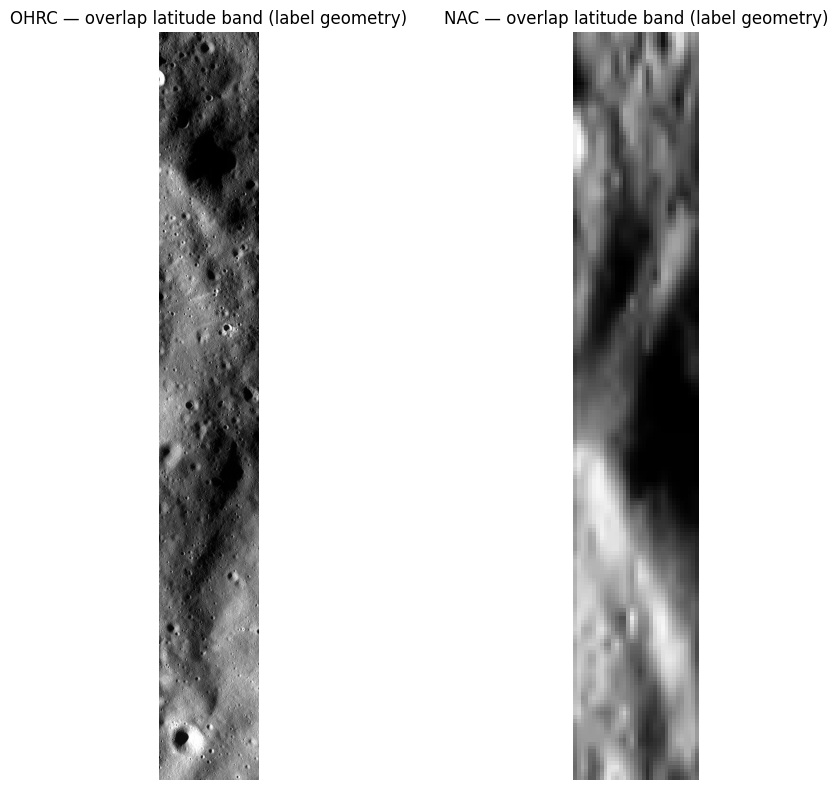

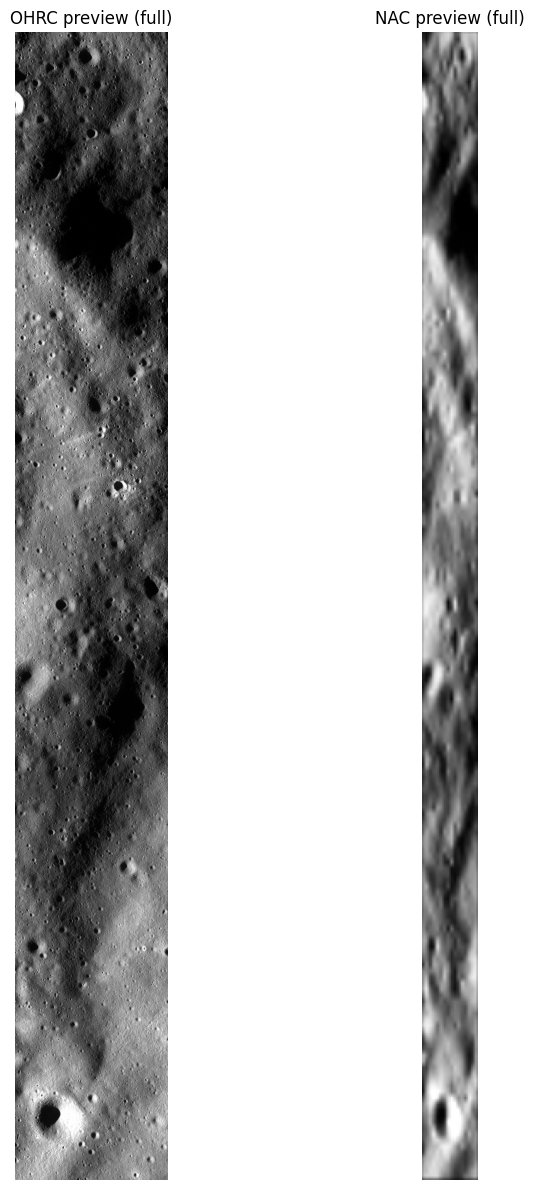

Saved: /content/drive/MyDrive/Chandrayaan_Registration/outputs/preview_viz/same_spot.png | /content/drive/MyDrive/Chandrayaan_Registration/outputs/preview_viz/full_previews.png


In [6]:
import numpy as _np
from pathlib import Path as _P
VIZ_ROOT = OUTPUT_ROOT / 'preview_viz'
VIZ_ROOT.mkdir(parents=True, exist_ok=True)
if globals().get('ref_preview', None) is None or globals().get('src_preview', None) is None:
    print('Skipping preview figures: reference pixels are not staged yet.')
else:
    _ssx = float(src_stride_x if src_stride_x else src_stride); _ssy = float(src_stride_y if src_stride_y else src_stride)
    _rsx = float(ref_stride_x if ref_stride_x else ref_stride); _rsy = float(ref_stride_y if ref_stride_y else ref_stride)
    _sh, _sw = src_meta['shape']; _rh, _rw = ref_meta['shape']
    _nlat0 = (ref_meta['corners']['upper_left_latitude'] + ref_meta['corners']['upper_right_latitude']) / 2
    _nlat1 = (ref_meta['corners']['lower_left_latitude'] + ref_meta['corners']['lower_right_latitude']) / 2
    _olat0 = (src_meta['corners']['upper_left_latitude'] + src_meta['corners']['upper_right_latitude']) / 2
    _olat1 = (src_meta['corners']['lower_left_latitude'] + src_meta['corners']['lower_right_latitude']) / 2
    _lo, _hi = max(min(_nlat0, _nlat1), min(_olat0, _olat1)), min(max(_nlat0, _nlat1), max(_olat0, _olat1))
    print(f'Common latitude band: {_lo:.4f} to {_hi:.4f}')
    if _hi <= _lo:
        print('No latitude overlap; skipping same-spot panel.')
    else:
        _or0 = int(_np.clip((_lo - _olat0) / (_olat1 - _olat0) * src_preview.shape[0], 0, src_preview.shape[0] - 1))
        _or1 = int(_np.clip((_hi - _olat0) / (_olat1 - _olat0) * src_preview.shape[0], 1, src_preview.shape[0]))
        _or0, _or1 = min(_or0, _or1), max(_or0, _or1)
        _nr0 = int(_np.clip((_lo - _nlat0) / (_nlat1 - _nlat0) * ref_preview.shape[0], 0, ref_preview.shape[0] - 1))
        _nr1 = int(_np.clip((_hi - _nlat0) / (_nlat1 - _nlat0) * ref_preview.shape[0], 1, ref_preview.shape[0]))
        _nr0, _nr1 = min(_nr0, _nr1), max(_nr0, _nr1)
        _src_band = src_preview[_or0:_or1, :]
        _ref_band = ref_preview[_nr0:_nr1, :]
        print(f'OHRC band rows: {_or0}-{_or1} {tuple(_src_band.shape)} | NAC band rows: {_nr0}-{_nr1} {tuple(_ref_band.shape)}')
        fig, ax = plt.subplots(1, 2, figsize=(12, 8))
        ax[0].imshow(_src_band, cmap='gray'); ax[0].set_title(f'{SENSOR.upper()} — overlap latitude band (label geometry)'); ax[0].axis('off')
        ax[1].imshow(_ref_band, cmap='gray'); ax[1].set_title('NAC — overlap latitude band (label geometry)'); ax[1].axis('off')
        plt.tight_layout(); plt.savefig(VIZ_ROOT / 'same_spot.png', dpi=90); plt.show()
        fig2, ax2 = plt.subplots(1, 2, figsize=(10, 12))
        ax2[0].imshow(src_preview, cmap='gray'); ax2[0].set_title(f'{SENSOR.upper()} preview (full)'); ax2[0].axis('off')
        ax2[1].imshow(ref_preview, cmap='gray'); ax2[1].set_title('NAC preview (full)'); ax2[1].axis('off')
        plt.tight_layout(); plt.savefig(VIZ_ROOT / 'full_previews.png', dpi=80); plt.show()
        print('Saved:', VIZ_ROOT / 'same_spot.png', '|', VIZ_ROOT / 'full_previews.png')


## 6. Coarse localization: source pixels → reference pixels

Full GSD: source 0.26 m/px -> reference 1.6053232034765612 m/px (base ratio=0.1620)
Overlap ROI too small; falling back to full reference preview.
Overlap ROI full-res: x=[0,2532] y=[701,16328] -> preview crop x=[0,33] y=[0,679]
  level j=-1 k=0.2025 shapes=(912, 121) vs (1698, 82): raw=26 inliers=16 ratio=0.615
  level j=+0 k=0.4049 shapes=(1825, 243) vs (1698, 82): raw=42 inliers=22 ratio=0.524
  level j=+1 k=0.8098 shapes=(3650, 486) vs (1698, 82): raw=45 inliers=10 ratio=0.222
  level j=+2 k=1.6196 shapes=(7300, 972) vs (1698, 82): raw=43 inliers=7 ratio=0.163
Best level: k_eff=0.4049 | Coarse SIFT matches: 42 | inliers: 22 | ratio: 0.524
Coarse method: sift_pyramid
Coarse source→reference H:
 [[ 3.34785467e-01 -4.61693913e-05 -3.19764068e+01]
 [-1.22237755e-02  5.79619273e-01 -2.87335045e+01]
 [-1.12719134e-06  4.59909826e-08  1.00000000e+00]]


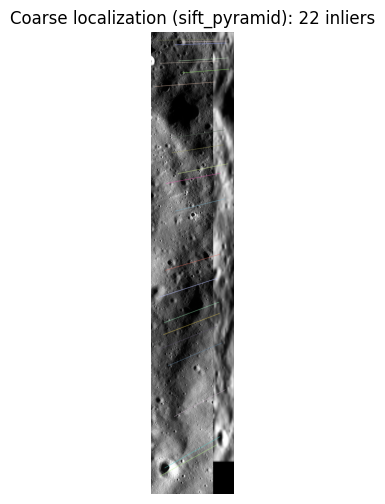

In [7]:
"""Coarse localization (GSD-first ordering).
Paper-B 4.1.2 requires a common GSD *before* feature matching: the OHRC
preview (0.26 m/px) is shrunk to the NAC ground scale (1.6 m/px) with
INTER_AREA, and the NAC preview is cropped to the metadata overlap ROI
so SIFT sees the same terrain at the same scale. Without this, a ~6x
scale gap leaves SIFT with ~0 repeatable features and the gate below
correctly refuses to continue.
"""
def overlap_bbox_in_ref(src_meta, ref_meta, margin_px=250):
    import numpy as np
    order = ['upper_left', 'upper_right', 'lower_right', 'lower_left']
    R = np.array([[ref_meta['corners'][f'{k}_latitude'], ref_meta['corners'][f'{k}_longitude']] for k in order], dtype=float)
    n_lines, n_samples = ref_meta['shape']
    pix = np.array([[0, 0], [0, n_samples - 1], [n_lines - 1, n_samples - 1], [n_lines - 1, 0]], dtype=float)
    A = np.column_stack([R, np.ones(4)])
    cr, *_ = np.linalg.lstsq(A, pix[:, 0], rcond=None)
    cc, *_ = np.linalg.lstsq(A, pix[:, 1], rcond=None)
    S = np.array([[src_meta['corners'][f'{k}_latitude'], src_meta['corners'][f'{k}_longitude']] for k in order], dtype=float)
    pr = cr[0] * S[:, 0] + cr[1] * S[:, 1] + cr[2]
    pc = cc[0] * S[:, 0] + cc[1] * S[:, 1] + cc[2]
    import math
    return (max(0, int(math.floor(pc.min())) - margin_px), max(0, int(math.floor(pr.min())) - margin_px),
            min(n_samples, int(math.ceil(pc.max())) + margin_px), min(n_lines, int(math.ceil(pr.max())) + margin_px))

def match_sift_global(a,b,max_features=6000,ratio=0.75):
    sift=cv2.SIFT_create(nfeatures=max_features)
    k1,d1=sift.detectAndCompute(a,None); k2,d2=sift.detectAndCompute(b,None)
    if d1 is None or d2 is None: return np.empty((0,2),np.float32),np.empty((0,2),np.float32),0
    knn=cv2.BFMatcher(cv2.NORM_L2).knnMatch(d1,d2,k=2)
    good=[m for m,n in knn if m.distance < ratio*n.distance]
    p1=np.float32([k1[m.queryIdx].pt for m in good]) if good else np.empty((0,2),np.float32)
    p2=np.float32([k2[m.trainIdx].pt for m in good]) if good else np.empty((0,2),np.float32)
    return p1,p2,len(good)

def fit_homography(p_src,p_ref,threshold=3.0):
    if len(p_src)<4: return None,None,0,0.0
    method=getattr(cv2,'USAC_MAGSAC',cv2.RANSAC)
    H,mask=cv2.findHomography(p_src,p_ref,method,threshold)
    if H is None or mask is None: return None,None,0,0.0
    mask=mask.ravel().astype(bool)
    return H,mask,int(mask.sum()),float(mask.mean())

if not globals().get('HAVE_REF', False) or not globals().get('HAVE_SRC', False):
    print('STOP POINT: add source pixels (.img or preview .png) and NAC pixels (.img or preview .png), then rerun from this cell.')
else:
    # --- pre-match: GSD-ratio base x scale pyramid + overlap ROI ---
    # Preview decimations differ per side (and per file), so no single scale
    # factor is safe. We try the Paper-B GSD ratio (0.162-class) at octave
    # steps, RANSAC each level, and keep the best by inlier count -- the
    # standard multi-scale search for cross-scale pairs (cf. B-4.1.2).
    src_gsd_f = float(src_meta['pixel_resolution_m']); ref_gsd_f = float(ref_meta['pixel_resolution_m'])
    gsd_scale = src_gsd_f / ref_gsd_f
    print(f'Full GSD: source {src_gsd_f} m/px -> reference {ref_gsd_f} m/px (base ratio={gsd_scale:.4f})')
    rx0, ry0, rx1, ry1 = overlap_bbox_in_ref(src_meta, ref_meta)
    _rsx = float(ref_stride_x if ref_stride_x else ref_stride); _rsy = float(ref_stride_y if ref_stride_y else ref_stride)
    qx0, qy0 = max(0, int(rx0 / _rsx)), max(0, int(ry0 / _rsy))
    qx1, qy1 = min(ref_preview.shape[1], max(qx0 + 64, int(np.ceil(rx1 / _rsx)))), min(ref_preview.shape[0], max(qy0 + 64, int(np.ceil(ry1 / _rsy))))
    if qx1 - qx0 < 64 or qy1 - qy0 < 64:
        print('Overlap ROI too small; falling back to full reference preview.')
        qx0, qy0, qx1, qy1 = 0, 0, ref_preview.shape[1], ref_preview.shape[0]
    ref_prev_roi_base = ref_preview[qy0:qy1, qx0:qx1]
    print(f'Overlap ROI full-res: x=[{rx0},{rx1}] y=[{ry0},{ry1}] -> preview crop x=[{qx0},{qx1}] y=[{qy0},{qy1}]')
    _ssx = float(src_stride_x if src_stride_x else src_stride); _ssy = float(src_stride_y if src_stride_y else src_stride)
    coarse_method = 'sift_pyramid'
    best = None  # (n_inliers, k_eff, u, src_try, ref_try, p_s, p_r, Hc, mc)
    for _j in (-1, 0, 1, 2):
        _k = gsd_scale * (2.0 ** _j)
        _nw, _nh = max(1, int(round(src_preview.shape[1] * _k))), max(1, int(round(src_preview.shape[0] * _k)))
        # Small uniform upscale (capped: must NOT equalize scales across levels).
        _u = 1.0
        _need = min(_nw, _nh, ref_prev_roi_base.shape[0], ref_prev_roi_base.shape[1])
        if _need < 96:
            _u = min(2.5, 96.0 / _need)
        _ke = _k * _u
        _src_try = cv2.resize(src_preview, (max(1, int(round(src_preview.shape[1] * _ke))), max(1, int(round(src_preview.shape[0] * _ke)))), interpolation=cv2.INTER_AREA if _ke < 1.0 else cv2.INTER_LINEAR)
        _ref_try = cv2.resize(ref_prev_roi_base, None, fx=_u, fy=_u, interpolation=cv2.INTER_LINEAR) if _u > 1.0 else ref_prev_roi_base
        _ps, _pr, _nr = match_sift_global(enhance_lunar(_src_try), enhance_lunar(_ref_try), max_features=8000)
        _Hc, _mc, _ni, _ir = fit_homography(_ps, _pr, RANSAC_THRESH_PX)
        print(f'  level j={_j:+d} k={_ke:.4f} shapes={_src_try.shape} vs {_ref_try.shape}: raw={_nr} inliers={_ni} ratio={round(float(_ir),3)}')
        if _Hc is not None and (best is None or _ni > best[0]):
            best = (_ni, _ke, _u, _src_try, _ref_try, _ps, _pr, _Hc, _mc)
    if best is None or best[0] < 8:
        # Image evidence exhausted: fall back to label geometry (Paper-A corner
        # method). Similarity from the 4 PDS4 corners is good to tens of px;
        print('WARNING: image coarse match failed at all levels; falling back to metadata-corner similarity (coarse_method=metadata_corners).')
        # Exact 4-point homography (deterministic). A similarity is WRONG here:
        # the source strip crosses the reference frame diagonally, so the
        # quads are not similar; the projective fit is exact at the corners
        # and good to tens of px inside -- plenty for padded ROI extraction.
        _order = ['upper_left', 'upper_right', 'lower_right', 'lower_left']
        _R_MOON = 1737400.0
        _rl = np.array([[ref_meta['corners'][f'{k}_latitude'], ref_meta['corners'][f'{k}_longitude']] for k in _order], dtype=float)
        _la0 = float(np.deg2rad(_rl[:, 0].mean()))
        _nl, _ns = ref_meta['shape']
        _pix = np.array([[0, 0], [_ns - 1, 0], [_ns - 1, _nl - 1], [0, _nl - 1]], dtype=np.float32)
        _rm = (np.stack([_R_MOON * np.cos(_la0) * np.deg2rad(_rl[:, 1]), _R_MOON * np.deg2rad(_rl[:, 0])], axis=1)).astype(np.float32)
        _Hm = cv2.getPerspectiveTransform(_rm, _pix)
        _sk = np.array([[src_meta['corners'][f'{k}_latitude'], src_meta['corners'][f'{k}_longitude']] for k in _order], dtype=float)
        _sm = (np.stack([_R_MOON * np.cos(_la0) * np.deg2rad(_sk[:, 1]), _R_MOON * np.deg2rad(_sk[:, 0])], axis=1)).astype(np.float32)
        _ref4 = cv2.perspectiveTransform(_sm.reshape(-1, 1, 2), _Hm).reshape(-1, 2).astype(np.float32)
        _sh, _sw = src_meta['shape']
        _src4 = np.array([[0, 0], [_sw - 1, 0], [_sw - 1, _sh - 1], [0, _sh - 1]], dtype=np.float32)
        H_full = cv2.getPerspectiveTransform(_src4, _ref4).astype(float)
        coarse_method = 'metadata_corners'
        p_s_c = np.empty((0, 2), np.float32); p_r_c = np.empty((0, 2), np.float32)
        mc = np.empty((0,), bool); n_raw = 0; ni = 0; ir = 0.0
        Hc = H_full.copy()
        src_prev_common, ref_prev_roi = src_preview, ref_prev_roi_base
    else:
        ni, k_eff, _u_win, src_prev_common, _ref_win, p_s_c, p_r_c, Hc, mc = best
        n_raw = len(p_s_c)
        ir = ni / max(n_raw, 1)
        # Hc maps winning-level source coords (= D(k_eff) @ preview coords) to
        # winning-level ROI coords (= ROI-crop coords scaled by _u_win).
        _SS = np.diag([_ssx, _ssy, 1.0]); _SR = np.diag([_rsx, _rsy, 1.0])
        _DK = np.diag([k_eff, k_eff, 1.0])
        _TC = np.array([[1, 0, qx0], [0, 1, qy0], [0, 0, 1]], dtype=float)
        _DUINV = np.diag([1.0 / _u_win, 1.0 / _u_win, 1.0])
        H_full = _SR @ _TC @ _DUINV @ Hc @ _DK @ np.linalg.inv(_SS)
        ref_prev_roi = _ref_win
        print(f'Best level: k_eff={k_eff:.4f} | Coarse SIFT matches: {n_raw} | inliers: {ni} | ratio: {round(float(ir),3)}')
    print('Coarse method:', coarse_method)
    print('Coarse source→reference H:\n', H_full)
    # ----------------------------------------------------------------------
    # Visualize coarse correspondences (reference side shown as the matched ROI).
    def show_matches(a,b,p1,p2,mask=None,maxn=150,title='matches'):
        if mask is not None and len(mask) == len(p1): p1,p2=p1[mask],p2[mask]
        n=min(maxn,len(p1)); idx=np.linspace(0,len(p1)-1,n,dtype=int) if n else []
        canvas=np.zeros((max(a.shape[0],b.shape[0]),a.shape[1]+b.shape[1]),np.uint8)
        canvas[:a.shape[0],:a.shape[1]]=a; canvas[:b.shape[0],a.shape[1]:]=b
        vis=cv2.cvtColor(canvas,cv2.COLOR_GRAY2RGB)
        rng=np.random.default_rng(0)
        for j in idx:
            q1=np.round(p1[j]).astype(int); q2=np.round(p2[j]).astype(int)+[a.shape[1],0]
            c=tuple(int(x) for x in rng.integers(80,255,3)); cv2.line(vis,tuple(q1),tuple(q2),c,1,cv2.LINE_AA)
        plt.figure(figsize=(14,6)); plt.imshow(vis); plt.title(title); plt.axis('off'); plt.show()
    if len(p_s_c):
        show_matches(src_prev_common,ref_prev_roi,p_s_c,p_r_c,mc,title=f'Coarse localization ({coarse_method}): {ni} inliers')
    else:
        print('No coarse image matches to draw; continuing on metadata geometry.')


## 7. Use the coarse transform to extract the real overlap

In [8]:
def project_points(H, pts):
    return cv2.perspectiveTransform(np.asarray(pts,np.float32).reshape(-1,1,2),H).reshape(-1,2)

def clamp_bbox(x0,y0,x1,y1,w,h,pad=0):
    return (max(0,int(math.floor(x0-pad))), max(0,int(math.floor(y0-pad))),
            min(w,int(math.ceil(x1+pad))), min(h,int(math.ceil(y1+pad))))

if globals().get('HAVE_REF', False) and globals().get('HAVE_SRC', False):
    sh,sw=src_meta['shape']; rh,rw=ref_meta['shape']
    src_corners=np.array([[0,0],[sw-1,0],[sw-1,sh-1],[0,sh-1]],np.float32)
    ref_proj=project_points(H_full,src_corners)
    rx0,ry0=ref_proj.min(axis=0); rx1,ry1=ref_proj.max(axis=0)
    ref_bbox=clamp_bbox(rx0,ry0,rx1,ry1,rw,rh,pad=250)
    print('Reference ROI bbox (x0,y0,x1,y1):',ref_bbox)
    if ref_bbox[2]-ref_bbox[0] < 100 or ref_bbox[3]-ref_bbox[1] < 100:
        raise RuntimeError('Projected overlap is too small; coarse transform is probably wrong.')

    # Inverse-project reference ROI corners to source raw pixels.
    Hinv=np.linalg.inv(H_full)
    x0,y0,x1,y1=ref_bbox
    rc=np.array([[x0,y0],[x1-1,y0],[x1-1,y1-1],[x0,y1-1]],np.float32)
    sc=project_points(Hinv,rc)
    sx0,sy0=sc.min(axis=0); sx1,sy1=sc.max(axis=0)
    src_bbox=clamp_bbox(sx0,sy0,sx1,sy1,sw,sh,pad=150)
    print('Source ROI bbox (x0,y0,x1,y1):   ',src_bbox)

    # Read only the source ROI and reference ROI.
    sx0,sy0,sx1,sy1=src_bbox
    if src_mm is not None:
        source_raw_roi=np.asarray(src_mm[sy0:sy1,sx0:sx1])
    else:
        # PNG rapid-look: map the full-res source bbox into PNG-native pixels.
        qx0,qy0=max(0,int(sx0/src_png_sx)),max(0,int(sy0/src_png_sy))
        qx1,qy1=min(src_png_native.shape[1],int(np.ceil(sx1/src_png_sx))),min(src_png_native.shape[0],int(np.ceil(sy1/src_png_sy)))
        source_raw_roi=np.asarray(src_png_native[qy0:qy1,qx0:qx1])
        print(f'Source ROI from preview PNG (native {src_png_native.shape} -> ROI {source_raw_roi.shape})')
    if ref_mm is not None:
        reference_raw_roi=np.asarray(ref_mm[y0:y1,x0:x1])
    else:
        # PNG rapid-look: map the full-res reference bbox into PNG-native pixels.
        px0,py0=max(0,int(x0/ref_png_sx)),max(0,int(y0/ref_png_sy))
        px1,py1=min(ref_png_native.shape[1],int(np.ceil(x1/ref_png_sx))),min(ref_png_native.shape[0],int(np.ceil(y1/ref_png_sy)))
        reference_raw_roi=np.asarray(ref_png_native[py0:py1,px0:px1])
        print(f'Reference ROI from preview PNG (native {ref_png_native.shape} -> ROI {reference_raw_roi.shape})')
    print('Raw ROI shapes:',source_raw_roi.shape, reference_raw_roi.shape)
    # ROI ground-scale bookkeeping (raw units per ROI px) for the GSD cell.
    # Memmap path reads raw pixels (scale 1); PNG path reads preview natives.
    if src_mm is not None:
        roi_src_origin_raw=(float(sx0),float(sy0)); roi_src_scale=(1.0,1.0)
    else:
        roi_src_origin_raw=(float(qx0*src_png_sx),float(qy0*src_png_sy)); roi_src_scale=(float(src_png_sx),float(src_png_sy))
    if ref_mm is not None:
        roi_ref_origin_raw=(float(x0),float(y0)); roi_ref_scale=(1.0,1.0)
    else:
        roi_ref_origin_raw=(float(px0*ref_png_sx),float(py0*ref_png_sy)); roi_ref_scale=(float(ref_png_sx),float(ref_png_sy))
    print('ROI scales (raw px per ROI px): src=',roi_src_scale,'ref=',roi_ref_scale)

Reference ROI bbox (x0,y0,x1,y1): (0, 0, 2532, 52224)
Source ROI bbox (x0,y0,x1,y1):    (0, 0, 7785, 90148)
Source ROI from preview PNG (native (9014, 1200) -> ROI (9014, 779))
Reference ROI from preview PNG (native (679, 33) -> ROI (679, 33))
Raw ROI shapes: (9014, 779) (679, 33)
ROI scales (raw px per ROI px): src= (10.0, 10.00088750832039) ref= (76.72727272727273, 76.91310751104565)


## 8. Common-GSD conversion

In [9]:
if globals().get('HAVE_REF', False) and globals().get('HAVE_SRC', False):
    source_gsd=float(src_meta['pixel_resolution_m']); ref_gsd=float(ref_meta['pixel_resolution_m'])
    # Ground scale of each ROI's pixels (m/px), whatever array they came from.
    sgsx=source_gsd*roi_src_scale[0]; sgsy=source_gsd*roi_src_scale[1]
    rgsx=ref_gsd*roi_ref_scale[0]; rgsy=ref_gsd*roi_ref_scale[1]
    fine_resample_f=((sgsx+sgsy)/2)/((rgsx+rgsy)/2)
    print(f'ROI ground scales: source {sgsx:.3f}/{sgsy:.3f} m/px -> reference {rgsx:.3f}/{rgsy:.3f} m/px | resample f={fine_resample_f:.5f}')
    if fine_resample_f <= 0: raise ValueError('Invalid ROI scales.')
    interp=cv2.INTER_LINEAR if src_meta.get('sun_elevation_deg') is None or src_meta.get('sun_elevation_deg') < 20 else cv2.INTER_CUBIC
    new_w=max(1,int(round(source_raw_roi.shape[1]*fine_resample_f)))
    new_h=max(1,int(round(source_raw_roi.shape[0]*fine_resample_f)))
    source_common=cv2.resize(source_raw_roi,(new_w,new_h),interpolation=interp if fine_resample_f>=1.0 else cv2.INTER_AREA)
    reference_common=reference_raw_roi.copy()

    # common-local -> raw source coords; raw reference -> ROI-local coords.
    _ssx,_ssy=roi_src_scale; _osx,_osy=roi_src_origin_raw
    _rsx,_rsy=roi_ref_scale; _orx,_ory=roi_ref_origin_raw
    S_inv=np.array([[_ssx/fine_resample_f,0,_osx],[0,_ssy/fine_resample_f,_osy],[0,0,1]],np.float64)
    T_ref=np.array([[1/_rsx,0,-_orx/_rsx],[0,1/_rsy,-_ory/_rsy],[0,0,1]],np.float64)
    H_common=T_ref @ H_full @ S_inv
    print('Common-scale source shape:',source_common.shape,'reference ROI:',reference_common.shape)


ROI ground scales: source 2.600/2.600 m/px -> reference 123.172/123.470 m/px | resample f=0.02108
Common-scale source shape: (190, 16) reference ROI: (679, 33)


## 9. Radiometric enhancement for correspondence matching

Use contrast normalization/CLAHE for the matcher. The earlier code applied `CLAHE → invert → dilate → full SVD/PCA` to the entire image. The full-image PCA is unnecessarily expensive and the inversion/dilation can alter crater boundaries; therefore this notebook keeps the enhancement conservative and reversible.

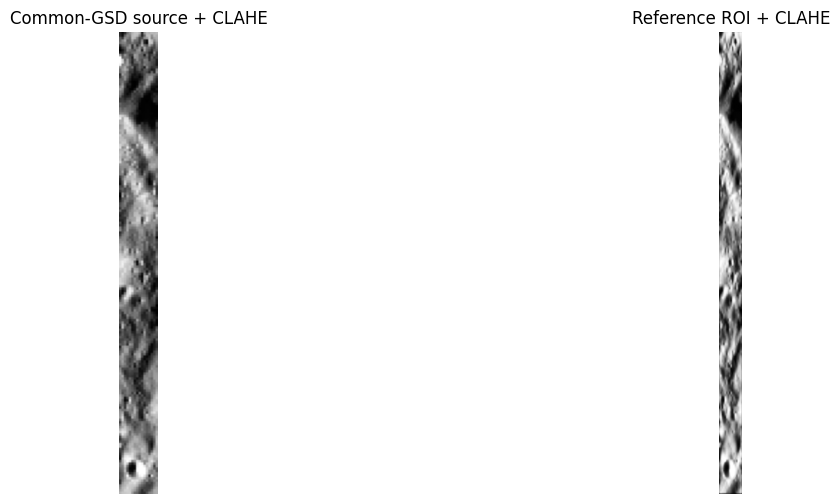

In [10]:
if globals().get('HAVE_REF', False) and globals().get('HAVE_SRC', False):
    src8=enhance_lunar(source_common, gamma=1.0)
    ref8=enhance_lunar(reference_common, gamma=1.0)
    fig,ax=plt.subplots(1,2,figsize=(14,6))
    ax[0].imshow(src8,cmap='gray'); ax[0].set_title('Common-GSD source + CLAHE'); ax[0].axis('off')
    ax[1].imshow(ref8,cmap='gray'); ax[1].set_title('Reference ROI + CLAHE'); ax[1].axis('off')
    plt.show()

## 10. Warp with the coarse geometry before fine matching

This converts the large localization problem into a residual-registration problem. The source is warped into the reference ROI using the coarse transform; SuperGlue/SIFT then estimates a fine residual transform.

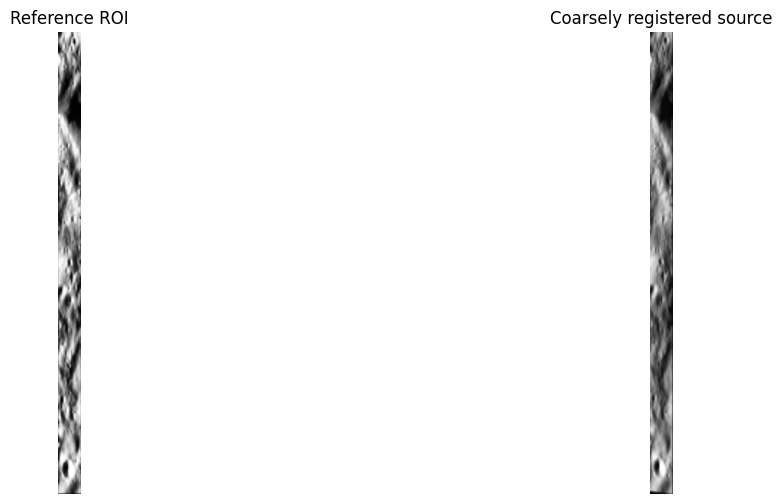

Coarse-warp check: NCC=0.822 over 22385 valid px (expect >0.15 if coarse ROI is right)


In [11]:
def warp_same_size(src, shape, H):
    return cv2.warpPerspective(src,H,(shape[1],shape[0]),flags=cv2.INTER_LINEAR,
                               borderMode=cv2.BORDER_CONSTANT,borderValue=0)

if globals().get('HAVE_REF', False) and globals().get('HAVE_SRC', False):
    coarse_warp=warp_same_size(src8,ref8.shape,H_common)
    fig,ax=plt.subplots(1,2,figsize=(14,6))
    ax[0].imshow(ref8,cmap='gray'); ax[0].set_title('Reference ROI'); ax[0].axis('off')
    ax[1].imshow(coarse_warp,cmap='gray'); ax[1].set_title('Coarsely registered source'); ax[1].axis('off')
    plt.show()
    # Sanity: zero-mean NCC between coarse warp and reference (valid pixels only).
    _vm=coarse_warp>0
    _a=ref8.astype(np.float32); _b=coarse_warp.astype(np.float32)
    _a-= _a[_vm].mean() if _vm.any() else 0; _b-= _b[_vm].mean() if _vm.any() else 0
    _den=np.sqrt((_a[_vm]**2).sum()*(_b[_vm]**2).sum())
    coarse_ncc=float((_a[_vm]*_b[_vm]).sum()/_den) if _den>0 else 0.0
    print(f'Coarse-warp check: NCC={coarse_ncc:.3f} over {int(_vm.sum())} valid px (expect >0.15 if coarse ROI is right)')


## 11. Fine correspondence matching

The local matcher now sees images in approximately the same pixel frame. SuperGlue is the primary learned matcher when available; SIFT is always available as a fallback/baseline.

In [12]:
def resize_keep_scale(img,max_side):
    h,w=img.shape[:2]; s=min(1.0,max_side/max(h,w))
    if s==1.0:return img,1.0
    return cv2.resize(img,(max(1,int(round(w*s))),max(1,int(round(h*s)))),interpolation=cv2.INTER_AREA),s

def tiled_sift(a,b,tile=TILE_PX,overlap=TILE_OVERLAP,ratio=0.75):
    sift=cv2.SIFT_create(nfeatures=0)
    step=max(128,tile-overlap); H,W=b.shape
    ps,pr,pc=[],[],[]
    for y in range(0,H,step):
        for x in range(0,W,step):
            y1=min(y+tile,H); x1=min(x+tile,W)
            aa=a[y:y1,x:x1]; bb=b[y:y1,x:x1]
            if aa.shape!=bb.shape or aa.size<256 or float(np.std(bb))<2: continue
            k1,d1=sift.detectAndCompute(aa,None); k2,d2=sift.detectAndCompute(bb,None)
            if d1 is None or d2 is None: continue
            good=[]
            for pair in cv2.BFMatcher(cv2.NORM_L2).knnMatch(d1,d2,k=2):
                if len(pair)==2 and pair[0].distance < ratio*pair[1].distance: good.append(pair[0])
            for m in good:
                ps.append(np.array(k1[m.queryIdx].pt)+[x,y]); pr.append(np.array(k2[m.trainIdx].pt)+[x,y]); pc.append(1-m.distance/(pair[1].distance+1e-9) if False else 1.0)
    if not ps:return np.empty((0,2),np.float32),np.empty((0,2),np.float32),np.empty((0,),np.float32)
    return np.asarray(ps,np.float32),np.asarray(pr,np.float32),np.asarray(pc,np.float32)

def load_superglue():
    if not USE_SUPERGLUE: return None
    sg_root=Path('/content/SuperGluePretrainedNetwork')
    if not (sg_root/'models'/'matching.py').exists():
        print('SuperGlue repo not available; using SIFT.')
        return None
    sys.path.insert(0,str(sg_root))
    from models.matching import Matching
    device='cuda' if __import__('torch').cuda.is_available() else 'cpu'
    cfg={'superpoint':{'nms_radius':4,'keypoint_threshold':0.003,'max_keypoints':4096},
         'superglue':{'weights':'outdoor','sinkhorn_iterations':20,'match_threshold':0.2}}
    return Matching(cfg).eval().to(device),device

@torch.no_grad()
def sg_match_tile(matcher,device,a,b):
    from models.utils import frame2tensor
    t0=frame2tensor(a.astype(np.float32),device); t1=frame2tensor(b.astype(np.float32),device)
    pred=matcher({'image0':t0,'image1':t1})
    pred={k:v[0].detach().cpu().numpy() for k,v in pred.items()}
    k0,k1=pred['keypoints0'],pred['keypoints1']; matches=pred['matches0']; conf=pred['matching_scores0']
    valid=matches>-1
    return k0[valid],k1[matches[valid]],conf[valid]

def tiled_superglue(matcher,device,a,b,tile=TILE_PX,overlap=TILE_OVERLAP,max_side=MAX_MATCH_SIDE):
    step=max(128,tile-overlap); H,W=b.shape; S=[];R=[];C=[];count=0
    for y in range(0,H,step):
        for x in range(0,W,step):
            if count>=MAX_LOCAL_TILES: break
            y1=min(y+tile,H); x1=min(x+tile,W)
            aa=a[y:y1,x:x1]; bb=b[y:y1,x:x1]
            if aa.shape!=bb.shape or aa.size<256 or float(np.std(bb))<2: continue
            ar,sa=resize_keep_scale(aa,max_side); br,sb=resize_keep_scale(bb,max_side)
            p0,p1,c=sg_match_tile(matcher,device,ar,br)
            if len(p0):
                S.append(p0/sa+[x,y]); R.append(p1/sb+[x,y]); C.append(c)
            count+=1
        if count>=MAX_LOCAL_TILES: break
    if not S:return np.empty((0,2),np.float32),np.empty((0,2),np.float32),np.empty((0,),np.float32)
    return np.concatenate(S),np.concatenate(R),np.concatenate(C)

if globals().get('HAVE_REF', False) and globals().get('HAVE_SRC', False):
    matcher_info=load_superglue()
    if matcher_info is not None:
        matcher,device=matcher_info
        mk_src_w,mk_ref,mconf=tiled_superglue(matcher,device,coarse_warp,ref8)
        matcher_used='SuperGlue'
    else:
        mk_src_w,mk_ref,mconf=tiled_sift(coarse_warp,ref8)
        matcher_used='SIFT'
    print('Fine matcher:',matcher_used,'| raw matches:',len(mk_src_w))
    if len(mk_src_w) < max(MIN_INLIERS, 25) and matcher_used != 'SIFT-relaxed':
        _s2,_r2,_c2=tiled_sift(coarse_warp,ref8,ratio=0.80)
        print('Relaxed-SIFT retry (ratio=0.80): raw matches:',len(_s2))
        if len(_s2) > len(mk_src_w):
            mk_src_w,mk_ref,mconf=_s2,_r2,_c2; matcher_used='SIFT-relaxed'
            print('Kept relaxed set:',len(mk_src_w))

Loaded SuperPoint model
Loaded SuperGlue model ("outdoor" weights)
Fine matcher: SuperGlue | raw matches: 9
Relaxed-SIFT retry (ratio=0.80): raw matches: 74
Kept relaxed set: 74


## 12. Robust geometry + uniform spatial distribution

First fit a residual homography with MAGSAC/RANSAC. Then select high-confidence inliers across an image grid and re-fit. This **enforces** spatial coverage rather than merely reporting it.

In [13]:
def uniform_select(p_src,p_ref,conf,mask,shape,grid=(8,8),max_per_cell=12):
    idx=np.where(mask)[0]
    if len(idx)==0:return idx
    h,w=shape; gh,gw=grid
    gx=np.clip((p_ref[idx,0]/max(w,1)*gw).astype(int),0,gw-1)
    gy=np.clip((p_ref[idx,1]/max(h,1)*gh).astype(int),0,gh-1)
    chosen=[]
    for cy in range(gh):
        for cx in range(gw):
            ids=idx[(gx==cx)&(gy==cy)]
            if len(ids):
                order=ids[np.argsort(conf[ids])[::-1]]
                chosen.extend(order[:max_per_cell].tolist())
    return np.asarray(chosen,dtype=int)

def reproj_errors(p_src,p_ref,H):
    q=project_points(H,p_src); return np.linalg.norm(q-p_ref,axis=1)

def coverage(p,shape,grid=(8,8)):
    if len(p)==0:return 0.0
    h,w=shape; gh,gw=grid
    gx=np.clip((p[:,0]/max(w,1)*gw).astype(int),0,gw-1)
    gy=np.clip((p[:,1]/max(h,1)*gh).astype(int),0,gh-1)
    return len(set(zip(gx.tolist(),gy.tolist())))/(gh*gw)

if globals().get('HAVE_REF', False) and globals().get('HAVE_SRC', False):
    Hres,m0,nin,ir=fit_homography(mk_src_w,mk_ref,RANSAC_THRESH_PX)
    if Hres is None or nin<MIN_INLIERS or ir<MIN_INLIER_RATIO:
        raise RuntimeError(f'Fine registration failed: {nin} inliers (raw={len(mk_src_w)}, matcher={matcher_used}, coarse={globals().get("coarse_method")}, '
                             f'src8={src8.shape} ref8={ref8.shape}, f={globals().get("fine_resample_f")}, ncc={globals().get("coarse_ncc"):.3f if isinstance(globals().get("coarse_ncc"), float) else globals().get("coarse_ncc")}). '
                             'Read: raw~0 means ROIs do not overlap (check coarse H/ROI shapes); raw>>0 with 0 inliers means coarse warp is off (check NCC).')
    idx_uniform=uniform_select(mk_src_w,mk_ref,mconf,m0,ref8.shape,UNIFORM_GRID,MAX_POINTS_PER_CELL)
    Hres2,m2,nin2,ir2=fit_homography(mk_src_w[idx_uniform],mk_ref[idx_uniform],RANSAC_THRESH_PX)
    if Hres2 is not None and nin2>=4:
        Hres=Hres2
        final_src=mk_src_w[idx_uniform]
        final_ref=mk_ref[idx_uniform]
        final_mask=np.ones(len(final_src),dtype=bool)
        # Recompute inliers on the spatially selected set.
        e=reproj_errors(final_src,final_ref,Hres)
        final_mask=e<=RANSAC_THRESH_PX
    else:
        final_src=mk_src_w[m0]; final_ref=mk_ref[m0]; final_mask=np.ones(len(final_src),dtype=bool)
    final_src=final_src[final_mask]; final_ref=final_ref[final_mask]
    residual_rmse=float(np.sqrt(np.mean(reproj_errors(final_src,final_ref,Hres)**2)))
    residual_median=float(np.median(reproj_errors(final_src,final_ref,Hres)))
    final_coverage=coverage(final_ref,ref8.shape,UNIFORM_GRID)
    print(f'Final residual: {len(final_src)} inliers | ratio={len(final_src)/max(len(mk_src_w),1):.3f} | RMSE={residual_rmse:.3f}px | median={residual_median:.3f}px | coverage={final_coverage:.3f}')

Final residual: 68 inliers | ratio=0.919 | RMSE=0.627px | median=0.315px | coverage=0.609


## 13. Sub-pixel refinement

SIFT/SuperPoint coordinates are floating-point, but that alone is not a proof of sub-pixel registration accuracy. We refine the accepted source/reference points with `cornerSubPix` and keep the refinement only when it improves the geometric residual.

In [14]:
def refine_points(a,b,p0,p1,win=(5,5),max_shift=1.5):
    if len(p0)==0:return p0,p1
    # cornerSubPix throws on points outside (or within win of) the image border
    # (tile-edge keypoints routinely are). Keep only interior points; skip if <4.
    m = max(1, int(win[0]) + 1)
    inside = (p0[:,0]>=m)&(p0[:,0]<=a.shape[1]-1-m)&(p0[:,1]>=m)&(p0[:,1]<=a.shape[0]-1-m)& \
             (p1[:,0]>=m)&(p1[:,0]<=b.shape[1]-1-m)&(p1[:,1]>=m)&(p1[:,1]<=b.shape[0]-1-m)
    dropped = int(len(p0) - inside.sum())
    if dropped:
        print(f'Sub-pixel refine: dropped {dropped} border points (of {len(p0)})')
    p0, p1 = p0[inside], p1[inside]
    if len(p0)<4:
        print('Sub-pixel refine: too few interior points; keeping unrefined coordinates.')
        return p0,p1
    criteria=(cv2.TERM_CRITERIA_EPS+cv2.TERM_CRITERIA_MAX_ITER,50,1e-3)
    p0c=p0.astype(np.float32).reshape(-1,1,2).copy(); p1c=p1.astype(np.float32).reshape(-1,1,2).copy()
    cv2.cornerSubPix(a,p0c,win,(-1,-1),criteria)
    cv2.cornerSubPix(b,p1c,win,(-1,-1),criteria)
    q0=p0c.reshape(-1,2); q1=p1c.reshape(-1,2)
    if max_shift is not None:
        keep=(np.linalg.norm(q0-p0,axis=1)<=max_shift)&(np.linalg.norm(q1-p1,axis=1)<=max_shift)
        return q0[keep],q1[keep]
    return q0,q1

if globals().get('HAVE_REF', False) and globals().get('HAVE_SRC', False):
    before=np.sqrt(np.mean(reproj_errors(final_src,final_ref,Hres)**2)) if len(final_src) else np.inf
    if SUBPIXEL_REFINE and len(final_src)>=4:
        rp0,rp1=refine_points(src8,ref8,final_src,final_ref,SUBPIXEL_WIN,SUBPIXEL_MAX_SHIFT)
        Hsub,msub,nis,irs=fit_homography(rp0,rp1,RANSAC_THRESH_PX)
        after=np.sqrt(np.mean(reproj_errors(rp0[msub],rp1[msub],Hsub)**2)) if Hsub is not None and msub is not None and msub.any() else np.inf
        if Hsub is not None and after < before and nis>=4:
            Hres=Hsub; final_src=rp0[msub]; final_ref=rp1[msub]
            residual_rmse=float(after); residual_median=float(np.median(reproj_errors(final_src,final_ref,Hres)))
            print(f'Sub-pixel refinement accepted: RMSE {before:.4f} → {after:.4f} px')
        else:
            print(f'Sub-pixel refinement rejected: RMSE {before:.4f} → {after:.4f} px')
    print('Sub-pixel pass (<1 px):', residual_rmse < 1.0)

Sub-pixel refine: dropped 63 border points (of 68)
Sub-pixel refinement rejected: RMSE 0.6266 → inf px
Sub-pixel pass (<1 px): True


## 14. Compose the final transform and generate the registered product

In [15]:
if globals().get('HAVE_REF', False) and globals().get('HAVE_SRC', False):
    # H_common maps common-GSD source-local coordinates -> reference ROI.
    # Hres maps coarsely warped source coordinates -> reference ROI.
    # Therefore final H maps common-GSD source-local coordinates -> reference ROI.
    H_final=Hres @ H_common
    registered=warp_same_size(src8,ref8.shape,H_final)

    # Overlay and checkerboard diagnostics.
    overlay=np.zeros((*ref8.shape,3),np.uint8)
    overlay[...,0]=registered
    overlay[...,1]=ref8
    board=ref8.copy(); block=80
    for yy in range(0,board.shape[0],2*block):
        for xx in range(0,board.shape[1],2*block):
            board[yy:yy+block,xx:xx+block]=registered[yy:yy+block,xx:xx+block]
            board[yy+block:yy+2*block,xx+block:xx+2*block]=registered[yy+block:yy+2*block,xx+block:xx+2*block]

    fig,ax=plt.subplots(1,3,figsize=(18,6))
    ax[0].imshow(ref8,cmap='gray'); ax[0].set_title('Reference NAC'); ax[0].axis('off')
    ax[1].imshow(registered,cmap='gray'); ax[1].set_title('Registered source'); ax[1].axis('off')
    ax[2].imshow(overlay); ax[2].set_title('Overlay: R=source, G=reference'); ax[2].axis('off')
    plt.show()
    plt.figure(figsize=(7,7)); plt.imshow(board,cmap='gray'); plt.title('Checkerboard registration diagnostic'); plt.axis('off'); plt.show()

## 15. Save deliverables to Google Drive

Outputs:

- `registered_source.png` — visual registered product;
- `match_points.csv` — source/reference correspondence coordinates and confidence;
- `transform.json` — coarse, residual and final transforms plus ROI offsets;
- `metrics.json` — geometric quality metrics and run provenance.

The registered PNG/TIFF is a **pixel-frame product**. A true CRS-aware GeoTIFF should only be written after a validated NAC sensor model/geotransform is supplied; the earlier implementation's “re-anchor” dictionary was bookkeeping, not a full geospatial transform.

In [1]:
if globals().get('HAVE_REF', False) and globals().get('HAVE_SRC', False):
    run_dir=OUTPUT_ROOT / f'{SENSOR}_to_nac_{Path(SOURCE_IMG).stem}'
    run_dir.mkdir(parents=True,exist_ok=True)
    cv2.imwrite(str(run_dir/'registered_source.png'),registered)
    cv2.imwrite(str(run_dir/'reference_roi.png'),ref8)
    cv2.imwrite(str(run_dir/'coarse_warp.png'),coarse_warp)

    # Map local common-GSD source match coordinates back to original raw source pixels.
    # final_src are in the coarse-warp image frame; invert H_common to get common-GSD source-local coords.
    Hc_inv=np.linalg.inv(H_common)
    src_common_pts=project_points(Hc_inv,final_src)
    _fx=globals().get('fine_resample_f',gsd_scale)
    raw_src_pts=np.column_stack([src_common_pts[:,0]*roi_src_scale[0]/_fx+roi_src_origin_raw[0],src_common_pts[:,1]*roi_src_scale[1]/_fx+roi_src_origin_raw[1]])
    ref_full_pts=final_ref*np.array(roi_ref_scale)+np.array(roi_ref_origin_raw)
    errors=reproj_errors(final_src,final_ref,Hres)
    df=pd.DataFrame({'source_x_raw':raw_src_pts[:,0],'source_y_raw':raw_src_pts[:,1],
                     'reference_x_full':ref_full_pts[:,0],'reference_y_full':ref_full_pts[:,1],
                     'residual_error_px':errors})
    df.to_csv(run_dir/'match_points.csv',index=False)

    metrics={
        'sensor':SENSOR,'reference':'LRO_NAC','matcher':matcher_used,
        'reference_pixels':'preview_png_rapid_look' if globals().get('ref_is_preview_png', False) else 'full_img',
        'coarse_method':globals().get('coarse_method','sift_pyramid'),'source_pixels':'preview_png_rapid_look' if globals().get('src_is_preview_png', False) else 'full_img',
        'inlier_matches':int(len(mk_src_w)),'final_inliers':int(len(final_src)),
        'inlier_ratio':float(len(final_src)/max(len(mk_src_w),1)),
        'rmse':float(residual_rmse),'median_reprojection_error_px':float(residual_median),
        'uniform_grid_coverage':float(coverage(final_ref,ref8.shape,UNIFORM_GRID)),
        'subpixel_pass_lt_1px':bool(residual_rmse<1.0),
        'source_gsd_m':source_gsd,'reference_gsd_m':ref_gsd,'gsd_scale_source_to_reference':gsd_scale,
        'reference_roi_full_px':[int(x0),int(y0),int(x1),int(y1)],
        'source_roi_full_px':[int(sx0),int(sy0),int(sx1),int(sy1)],
    }
    (run_dir/'metrics.json').write_text(json.dumps(metrics,indent=2))
    transform={'H_coarse_raw_source_to_reference':H_full.tolist(),
               'H_common_gsd_source_local_to_reference_roi':H_common.tolist(),
               'H_residual_coarsewarp_to_reference_roi':Hres.tolist(),
               'H_final_common_source_to_reference_roi':H_final.tolist(),
               'source_roi_origin_raw':[int(sx0),int(sy0)],'reference_roi_origin_full':[int(x0),int(y0)],
               'gsd_scale':float(gsd_scale)}
    (run_dir/'transform.json').write_text(json.dumps(transform,indent=2))
    print('Saved outputs to:',run_dir)
    print(json.dumps(metrics,indent=2))